# Assembling a Reasonable Drone

[`sympy_drone.ipynb`](sympy_drone.ipynb) analysed one quadcopter. Here
the question is the one a builder faces first: **which parts?** A small
catalogue gives 108 possible combinations; most of them would not fly
well, overheat something, or cost too much.

| Part | Question | Tool |
|---|---|---|
| 1 | Which combinations satisfy the design rules? | `for` loops, `if / elif` conditions |
| 2 | Can the rules be counted algebraically? | Boolean algebra → polynomial in SymPy |
| 3 | Which valid build is the best value? | cost vs flight time |
| 4 | Will the arm hold? | beam bending, grain size (Hall–Petch), cracks (Griffith) |
| 5 | Making the frame and boards: photomask and laser | lithography resolution, laser eye safety |
| 6 | How far does the radio reach? | Friis link budget |
| 7 | Automating the check in a POSIX shell | `read`, `if`, and the exit status `$?` |

**All parts are generic and all prices illustrative** — they are the
right order of magnitude for hobby parts, not quotes for any product.
Every result is asserted in the cell that computes it.

In [1]:
import itertools
import math
import pathlib
import shutil
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

sys.path.insert(0, str(pathlib.Path.cwd().parent))     # the repository root, for dgs.*
from dgs.laser_safety import nominal_ocular_hazard_distance, optical_density_required

G, RHO_AIR = 9.81, 1.225
print("sympy", sp.__version__)

sympy 1.14.0


# Part 1 — The catalogue and the design rules

Each motor is listed with the propeller it is meant to spin and its
full-throttle thrust and current on a 4-cell (4S) battery. On a 3-cell
battery the voltage is ¾ as high; thrust and current both scale roughly
with voltage squared, so they drop to $(3/4)^2 \approx 56\%$.

**Design rules** (each is a yes/no question):

| Rule | Condition | Why |
|---|---|---|
| fits | propeller ≤ the frame's largest propeller | props must not hit each other |
| lift | thrust-to-weight ratio ≥ 2 | enough margin to climb and fight wind |
| esc | each motor's current ≤ the ESC rating | the speed controllers must not overheat |
| battery | total current ≤ C-rating × capacity | the battery must deliver the current safely |
| endurance | hover time ≥ 20 min | a useful flight |

Hover power uses the momentum-theory result from `sympy_drone.ipynb`,
$P = \sqrt{T^3/(2\rho A)}$ divided by a figure of merit (0.6) and a
drive efficiency (0.8), with 80 % of the battery usable.

In [2]:
frames = [
    {"name": "plastic 450", "mass": 0.28, "arm_m": 0.225, "max_prop_in": 10, "price": 25},
    {"name": "carbon 450",  "mass": 0.20, "arm_m": 0.225, "max_prop_in": 10, "price": 60},
    {"name": "carbon 350",  "mass": 0.15, "arm_m": 0.175, "max_prop_in": 8,  "price": 45},
]
motor_sets = [   # four motors with matching propellers; thrust and current per motor on 4S
    {"name": "2212 + 10in", "prop_in": 10, "thrust_N": 8.0,  "current_A": 15.0, "mass": 0.224, "price": 60},
    {"name": "2216 + 10in", "prop_in": 10, "thrust_N": 10.0, "current_A": 18.0, "mass": 0.288, "price": 90},
    {"name": "2207 + 8in",  "prop_in": 8,  "thrust_N": 9.0,  "current_A": 25.0, "mass": 0.160, "price": 80},
]
esc_sets = [
    {"name": "20 A", "rating_A": 20.0, "mass": 0.10, "price": 40},
    {"name": "30 A", "rating_A": 30.0, "mass": 0.12, "price": 55},
    {"name": "40 A", "rating_A": 40.0, "mass": 0.15, "price": 70},
]
batteries = [
    {"name": "4S 2200 30C", "cells": 4, "Ah": 2.2, "C": 30, "mass": 0.23, "price": 30},
    {"name": "4S 3000 25C", "cells": 4, "Ah": 3.0, "C": 25, "mass": 0.32, "price": 45},
    {"name": "4S 5000 20C", "cells": 4, "Ah": 5.0, "C": 20, "mass": 0.53, "price": 70},
    {"name": "3S 3000 30C", "cells": 3, "Ah": 3.0, "C": 30, "mass": 0.25, "price": 35},
]
electronics = {"mass": 0.10, "price": 80}      # flight controller, GPS, receiver


def evaluate(frame, motors, esc, battery):
    scale = (battery["cells"] / 4) ** 2                  # thrust and current vs voltage
    mass = frame["mass"] + motors["mass"] + esc["mass"] + battery["mass"] + electronics["mass"]
    thrust_to_weight = 4 * motors["thrust_N"] * scale / (mass * G)
    motor_current = motors["current_A"] * scale
    disc_area = 4 * math.pi * (motors["prop_in"] * 0.0254 / 2) ** 2
    hover_W = math.sqrt((mass * G) ** 3 / (2 * RHO_AIR * disc_area)) / (0.6 * 0.8)
    energy_Wh = 3.7 * battery["cells"] * battery["Ah"]
    rules = {
        "fits": motors["prop_in"] <= frame["max_prop_in"],
        "lift": thrust_to_weight >= 2.0,
        "esc": motor_current <= esc["rating_A"],
        "battery": 4 * motor_current <= battery["C"] * battery["Ah"],
        "endurance": 0.8 * energy_Wh / hover_W * 60 >= 20,
    }
    return {
        "name": f'{frame["name"]} | {motors["name"]} | {esc["name"]} | {battery["name"]}',
        "mass_kg": mass, "twr": thrust_to_weight, "hover_W": hover_W,
        "minutes": 0.8 * energy_Wh / hover_W * 60,
        "cost": frame["price"] + motors["price"] + esc["price"] + battery["price"] + electronics["price"],
        "rules": rules,
    }


builds, reasons = [], {}
for frame, motors, esc, battery in itertools.product(frames, motor_sets, esc_sets, batteries):
    build = evaluate(frame, motors, esc, battery)
    builds.append(build)
    r = build["rules"]
    if not r["fits"]:
        reason = "propellers too big for the frame"
    elif not r["lift"]:
        reason = "not enough thrust (TWR < 2)"
    elif not r["esc"]:
        reason = "motor current exceeds the ESC rating"
    elif not r["battery"]:
        reason = "battery cannot supply the current"
    elif not r["endurance"]:
        reason = "hover time under 20 minutes"
    else:
        reason = "VALID"
    build["verdict"] = reason
    reasons[reason] = reasons.get(reason, 0) + 1

print(f"{len(builds)} combinations checked\n")
for reason, count in sorted(reasons.items(), key=lambda item: -item[1]):
    print(f"  {count:3d}  {reason}")
valid = [b for b in builds if b["verdict"] == "VALID"]
assert len(builds) == 108 and len(valid) == reasons["VALID"]

108 combinations checked

   36  VALID
   24  propellers too big for the frame
   18  battery cannot supply the current
   17  hover time under 20 minutes
    9  motor current exceeds the ESC rating
    4  not enough thrust (TWR < 2)


The `if / elif` chain reports the **first** rule a build breaks, which
is what a person debugging a build wants to hear. It hides the fact
that many builds break several rules at once — the next part looks at
the rules all together.

# Part 2 — The rules as Boolean algebra, and as a polynomial

Name the five rules $f, l, e, b, d$ (fits, lift, esc, battery,
duration). A build is valid when

$$\text{valid} = f \wedge l \wedge e \wedge b \wedge d .$$

Translated to ordinary algebra on 0/1 values (AND becomes
multiplication), valid $= f\,l\,e\,b\,d$. **Summing that polynomial over
all builds counts the valid ones** — the same number the loop found,
with no `if` statements.

Add a second, softer requirement: a build is *reasonable* if it is
valid **and** either costs at most \$300 **or** hovers at least 25
minutes (willing to pay more for much longer flights). With $c$ = "cost
≤ \$300" and $t$ = "hover ≥ 25 min":

$$\text{reasonable} = f\,l\,e\,b\,d\,(c + t - ct) ,$$

using OR $\to$ $c + t - ct$.

In [3]:
f, l, e, b, d, c_ok, t_ok = sp.symbols("f l e b d c t")
valid_logic = sp.And(f, l, e, b, d)
reasonable_logic = sp.And(valid_logic, sp.Or(c_ok, t_ok))


def to_poly(expr):
    if isinstance(expr, sp.Symbol):
        return expr
    parts = [to_poly(arg) for arg in expr.args]
    if isinstance(expr, sp.And):
        return sp.Mul(*parts)
    if isinstance(expr, sp.Or):
        return 1 - sp.Mul(*[1 - part for part in parts])
    if isinstance(expr, sp.Not):
        return 1 - parts[0]
    raise TypeError(type(expr).__name__)


valid_poly = sp.expand(to_poly(valid_logic))
reasonable_poly = sp.expand(to_poly(reasonable_logic))
print("valid      =", valid_poly)
print("reasonable =", reasonable_poly)


def assignment(build):
    r = build["rules"]
    return {f: int(r["fits"]), l: int(r["lift"]), e: int(r["esc"]), b: int(r["battery"]), d: int(r["endurance"]),
            c_ok: int(build["cost"] <= 300), t_ok: int(build["minutes"] >= 25)}


valid_count = sum(valid_poly.subs(assignment(build)) for build in builds)
reasonable_count = sum(reasonable_poly.subs(assignment(build)) for build in builds)
print(f"\nsum of the 'valid' polynomial over all builds      = {valid_count}  (loop found {len(valid)})")
print(f"sum of the 'reasonable' polynomial over all builds = {reasonable_count}")
assert valid_count == len(valid)
assert reasonable_count == sum(1 for build in valid if build["cost"] <= 300 or build["minutes"] >= 25)

valid      = b*d*e*f*l
reasonable = -b*c*d*e*f*l*t + b*c*d*e*f*l + b*d*e*f*l*t

sum of the 'valid' polynomial over all builds      = 36  (loop found 36)
sum of the 'reasonable' polynomial over all builds = 29


**Are the rules independent?** If they were, the fraction of valid
builds would be the product of each rule's pass rate — the same
mistake about shared inputs met in
[`circuit_graph_compiler.ipynb`](circuit_graph_compiler.ipynb). They are
not independent, and the clearest test is pair by pair: if two rules
were independent, the fraction of builds passing both would equal the
product of their separate pass rates. The polynomial, evaluated build
by build, needs no independence assumption.

In [4]:
rule_names = list(builds[0]["rules"])
pass_rate = {name: np.mean([build["rules"][name] for build in builds]) for name in rule_names}
for name, rate in pass_rate.items():
    print(f"  {name:10s} passes in {rate * 100:5.1f} % of builds")

print("\n rule pair             both pass   product of rates   difference")
differences = {}
for first, second in itertools.combinations(rule_names, 2):
    joint = np.mean([build["rules"][first] and build["rules"][second] for build in builds])
    product_ = pass_rate[first] * pass_rate[second]
    differences[(first, second)] = joint - product_
    print(f"  {first:9s} {second:10s}  {joint * 100:5.1f} %        {product_ * 100:5.1f} %         {(joint - product_) * 100:+5.1f}")
largest = max(differences, key=lambda pair: abs(differences[pair]))
print(f"\nlargest dependence: {largest[0]} and {largest[1]} ({differences[largest] * 100:+.1f} points)")
assert abs(differences[largest]) > 0.05

  fits       passes in  77.8 % of builds
  lift       passes in  96.3 % of builds
  esc        passes in  91.7 % of builds
  battery    passes in  75.0 % of builds
  endurance  passes in  63.9 % of builds

 rule pair             both pass   product of rates   difference
  fits      lift         74.1 %         74.9 %          -0.8
  fits      esc          69.4 %         71.3 %          -1.9
  fits      battery      55.6 %         58.3 %          -2.8
  fits      endurance    43.5 %         49.7 %          -6.2
  lift      esc          88.0 %         88.3 %          -0.3
  lift      battery      71.3 %         72.2 %          -0.9
  lift      endurance    63.9 %         61.5 %          +2.4
  esc       battery      72.2 %         68.8 %          +3.5
  esc       endurance    58.3 %         58.6 %          -0.2
  battery   endurance    54.6 %         47.9 %          +6.7

largest dependence: battery and endurance (+6.7 points)


Positive differences mean the two rules tend to pass together: a big
battery satisfies both the current limit and the endurance rule.
Negative ones mean they compete: the small frame forces small
propellers, which cost endurance.

# Part 3 — The best-value build

Among valid builds, nobody should pick one that is both more expensive
**and** flies for less time than another. The builds that are not beaten
on both counts form the **Pareto front**; the sensible choice lies on it.

Pareto front (cheapest first):
  $250   22.6 min  TWR 3.19  1.02 kg  plastic 450 | 2212 + 10in | 20 A | 4S 3000 25C
  $275   28.5 min  TWR 2.64  1.23 kg  plastic 450 | 2212 + 10in | 20 A | 4S 5000 20C
  $310   31.5 min  TWR 2.83  1.15 kg  carbon 450 | 2212 + 10in | 20 A | 4S 5000 20C

most minutes per dollar: plastic 450 | 2212 + 10in | 20 A | 4S 5000 20C
  $275, 28.5 min hover, TWR 2.64, 1.23 kg


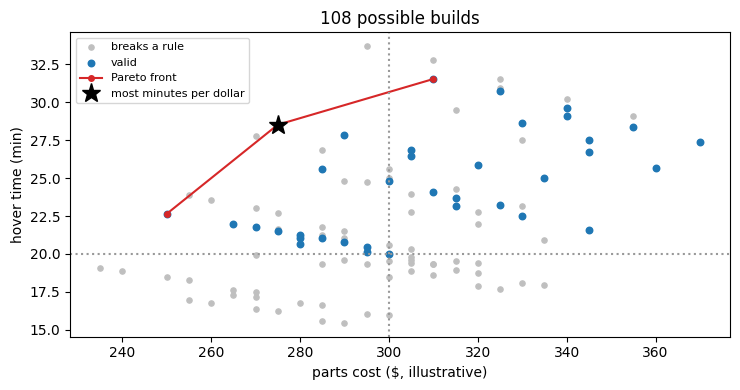

In [5]:
def pareto_front(candidates):
    front = []
    for build in candidates:
        beaten = any(other["cost"] <= build["cost"] and other["minutes"] >= build["minutes"]
                     and (other["cost"], other["minutes"]) != (build["cost"], build["minutes"])
                     for other in candidates)
        if not beaten:
            front.append(build)
    return sorted(front, key=lambda build: build["cost"])


front = pareto_front(valid)
print("Pareto front (cheapest first):")
for build in front:
    print(f"  ${build['cost']:3d}  {build['minutes']:5.1f} min  TWR {build['twr']:.2f}  {build['mass_kg']:.2f} kg  {build['name']}")

chosen = max(front, key=lambda build: build["minutes"] / build["cost"])
print(f"\nmost minutes per dollar: {chosen['name']}")
print(f"  ${chosen['cost']}, {chosen['minutes']:.1f} min hover, TWR {chosen['twr']:.2f}, {chosen['mass_kg']:.2f} kg")
assert chosen in valid

fig, ax = plt.subplots(figsize=(7.5, 4))
others = [build for build in builds if build["verdict"] != "VALID"]
ax.scatter([b_["cost"] for b_ in others], [b_["minutes"] for b_ in others], s=14, color="0.75", label="breaks a rule")
ax.scatter([b_["cost"] for b_ in valid], [b_["minutes"] for b_ in valid], s=22, color="C0", label="valid")
ax.plot([b_["cost"] for b_ in front], [b_["minutes"] for b_ in front], "C3-o", ms=4, label="Pareto front")
ax.plot(chosen["cost"], chosen["minutes"], "k*", ms=14, label="most minutes per dollar")
ax.axhline(20, color="0.6", ls=":"); ax.axvline(300, color="0.6", ls=":")
ax.set_xlabel("parts cost ($, illustrative)"); ax.set_ylabel("hover time (min)")
ax.set_title("108 possible builds"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Part 4 — Will the arm hold?

## Bending

Treat an arm as a cantilever: fixed at the body, motor thrust $T$ at
the tip, length $L$. The bending moment at the root is $M = TL$ and the
largest stress, at the tube's outer surface, is

$$\sigma = \frac{M\,c}{I}, \qquad I = \frac{\pi}{64}\left(D^4 - d^4\right), \quad c = \frac{D}{2}$$

for a tube of outer diameter $D$ and inner diameter $d$. The check
below uses an **aluminium tube**, 12 mm × 1 mm wall, so that the two
metal-specific ideas that follow apply.

In [6]:
T_s, L_s, D_s, d_s = sp.symbols("T L D d", positive=True)
I_tube = sp.pi / 64 * (D_s**4 - d_s**4)
sigma_expr = T_s * L_s * (D_s / 2) / I_tube
print("root bending stress sigma ="); sp.pprint(sp.simplify(sigma_expr))

motor_choice = next(m_ for m_ in motor_sets if m_["name"] in chosen["name"])
battery_choice = next(b_ for b_ in batteries if b_["name"] in chosen["name"])
frame_choice = next(f_ for f_ in frames if f_["name"] in chosen["name"])
tip_thrust = motor_choice["thrust_N"] * (battery_choice["cells"] / 4) ** 2
sigma_arm = float(sigma_expr.subs({T_s: tip_thrust, L_s: frame_choice["arm_m"], D_s: 0.012, d_s: 0.010}))
print(f"\nfull-throttle thrust {tip_thrust:.1f} N on a {frame_choice['arm_m'] * 100:.1f} cm arm "
      f"-> root stress {sigma_arm / 1e6:.1f} MPa")
assert 10e6 < sigma_arm < 60e6

root bending stress sigma =


 32⋅D⋅L⋅T  
───────────
  ⎛ 4    4⎞
π⋅⎝D  - d ⎠

full-throttle thrust 8.0 N on a 22.5 cm arm -> root stress 20.5 MPa


## Grain size: the Hall–Petch relation

A metal is a patchwork of tiny crystals (**grains**). Slip has to
restart at every grain boundary, so finer grains make a stronger
metal:

$$\sigma_y = \sigma_0 + \frac{k}{\sqrt{d_g}} ,$$

where $d_g$ is the grain diameter. The constants below
($\sigma_0 = 70$ MPa, $k = 0.12\ \text{MPa}\sqrt{\text{m}}$) are
illustrative, of the order quoted for aluminium alloys; real values
depend on the alloy and its heat treatment.

d(sigma_y)/d(d_g) = -k/(2*d_g**(3/2))  (negative: bigger grains, weaker metal)

 grain size   yield strength   safety factor on the arm
     1 um         190 MPa            9.3
    10 um         108 MPa            5.3
   100 um          82 MPa            4.0


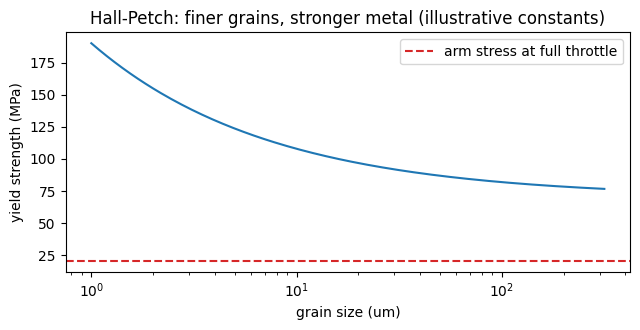

In [7]:
sigma0, k_hp, dg = sp.symbols("sigma_0 k d_g", positive=True)
hall_petch = sigma0 + k_hp / sp.sqrt(dg)
print("d(sigma_y)/d(d_g) =", sp.diff(hall_petch, dg), " (negative: bigger grains, weaker metal)")

hp = sp.lambdify(dg, hall_petch.subs({sigma0: 70e6, k_hp: 0.12e6}), "numpy")
grain_um = np.logspace(0, 2.5, 200)
print("\n grain size   yield strength   safety factor on the arm")
for size in (1, 10, 100):
    strength = hp(size * 1e-6)
    print(f"  {size:4d} um      {strength / 1e6:6.0f} MPa          {strength / sigma_arm:5.1f}")
assert hp(1e-6) > hp(1e-4)

plt.figure(figsize=(6.5, 3.4))
plt.semilogx(grain_um, hp(grain_um * 1e-6) / 1e6)
plt.axhline(sigma_arm / 1e6, color="C3", ls="--", label="arm stress at full throttle")
plt.xlabel("grain size (um)"); plt.ylabel("yield strength (MPa)")
plt.title("Hall-Petch: finer grains, stronger metal (illustrative constants)"); plt.legend()
plt.tight_layout(); plt.show()

## Cracks: Griffith's energy balance

A crack of length $2a$ in a plate under stress $\sigma$ releases
elastic energy $\pi\sigma^2a^2/E$ (per unit thickness) but costs surface
energy $4a\gamma$ (two faces). It grows when growing *lowers* the total
energy — the top of the energy curve, where $dU/da = 0$:

In [8]:
sigma_s, a_s, E_s, gamma_s = sp.symbols("sigma a E gamma", positive=True)
U = -sp.pi * sigma_s**2 * a_s**2 / E_s + 4 * a_s * gamma_s
fracture_stress = sp.solve(sp.Eq(sp.diff(U, a_s), 0), sigma_s)[0]
print("Griffith fracture stress sigma_f ="); sp.pprint(fracture_stress)
assert sp.simplify(fracture_stress - sp.sqrt(2 * E_s * gamma_s / (sp.pi * a_s))) == 0

# engineering form: sigma_f = K_IC / sqrt(pi a); critical crack a_c = (K_IC / sigma)^2 / pi
K_IC = 29e6                       # Pa sqrt(m), a commonly quoted value for 6061-T6 aluminium
a_critical = (K_IC / sigma_arm) ** 2 / math.pi
print(f"\nwith K_IC = 29 MPa sqrt(m), the arm at {sigma_arm / 1e6:.0f} MPa tolerates a crack up to "
      f"{a_critical * 100:.0f} cm -- far bigger than the arm")
crash_sigma = 20 * sigma_arm
print(f"a crash load 20x larger ({crash_sigma / 1e6:.0f} MPa) is past typical aluminium yield first: "
      f"the arm bends before it cracks")
assert a_critical > 0.1

Griffith fracture stress sigma_f =
√2⋅√E⋅√γ
────────
 √π⋅√a  

with K_IC = 29 MPa sqrt(m), the arm at 20 MPa tolerates a crack up to 64 cm -- far bigger than the arm
a crash load 20x larger (410 MPa) is past typical aluminium yield first: the arm bends before it cracks


So in normal flight an aluminium arm is limited by neither strength
nor cracking; it fails in crashes, by bending. That is why many frames
use carbon-fibre plates and tubes — stiff and light — and accept that
they break rather than bend.

# Part 5 — Making the parts: photomask and laser

## The flight-controller board: photomask resolution

Circuit boards are patterned with light through a **photomask**. With
a gap $g$ between mask and board, diffraction blurs edges, and the
smallest reliable feature is roughly

$$w_\text{min} \approx \sqrt{\lambda g} .$$

In [9]:
wavelength = 365e-9                           # mercury i-line, the classic UV exposure wavelength
print(" mask gap    smallest feature")
for gap_um in (0, 10, 100, 500):
    width = math.sqrt(wavelength * gap_um * 1e-6)
    print(f"  {gap_um:4d} um     {width * 1e6:6.1f} um" + ("   (contact: limited by other effects)" if gap_um == 0 else ""))
pcb_trace = 150e-6
print(f"\na typical fine PCB trace is {pcb_trace * 1e6:.0f} um: even a 500 um gap leaves a "
      f"{pcb_trace / math.sqrt(wavelength * 500e-6):.0f}x margin")
print("chip-scale features (well under 1 um) need projection optics instead: R = k1 * lambda / NA")
assert math.sqrt(wavelength * 500e-6) < pcb_trace

 mask gap    smallest feature
     0 um        0.0 um   (contact: limited by other effects)
    10 um        1.9 um
   100 um        6.0 um
   500 um       13.5 um

a typical fine PCB trace is 150 um: even a 500 um gap leaves a 11x margin
chip-scale features (well under 1 um) need projection optics instead: R = k1 * lambda / NA


## Cutting frame plates with a laser: eye safety

A hobby diode laser cutter (here: 5 W at 450 nm, blue) is a **Class 4**
laser: hazardous to the eye even from diffuse reflections, and a fire
hazard. Two numbers set the precautions:

- **NOHD** (nominal ocular hazard distance): how far the bare beam
  stays above the maximum permissible exposure (MPE);
- **OD** (optical density) of the eyewear: $\log_{10}(E/\text{MPE})$.

The calculation reuses this repository's `dgs.laser_safety` module.
The MPE of 25 W/m² is the rule-of-thumb visible-light value for a 0.25 s
exposure used there; a real assessment must take the MPE from the
current ANSI Z136.1 for the actual wavelength and exposure time. The
1 mrad divergence is a worst case (a collimated beam).

In [10]:
power, divergence, aperture, mpe = 5.0, 1e-3, 4e-3, 25.0
nohd = nominal_ocular_hazard_distance(power, divergence, mpe, aperture)
irradiance_at_aperture = power / (math.pi / 4 * aperture**2)
od = optical_density_required(irradiance_at_aperture, mpe)
print(f"5 W, 450 nm, 1 mrad, 4 mm beam:  NOHD = {nohd:.0f} m,  eyewear OD >= {od:.1f} at 450 nm")
assert nohd > 100 and od > 4

5 W, 450 nm, 1 mrad, 4 mm beam:  NOHD = 501 m,  eyewear OD >= 4.2 at 450 nm


A collimated 5 W beam stays above the eye limit for half a kilometre.
In practice the beam is focused, an enclosure blocks it, and the
practical rules are about keeping it inside that enclosure.

**A generic laser-safety training outline** (a starting checklist; it
does not replace your institution's Laser Safety Officer or the
current ANSI Z136.1 / Z136.8 requirements):

1. Hazard class and why: Class 4 — direct, specular and diffuse
   reflections; skin; fire.
2. Controls in order of effectiveness: enclosure and interlocks →
   key switch, warning signs, controlled area → procedures → eyewear.
3. Eyewear: correct **wavelength** and **OD** (computed above), checked
   before every use.
4. Materials: never cut PVC/vinyl (corrosive chlorine gas); carbon
   fibre produces hazardous dust and fumes — use extraction or a
   different process.
5. Fire: never leave a running cutter; extinguisher at hand.
6. Alignment: lowest practical power; no reflective tools or jewellery
   in the beam path.
7. Incidents: who to call, what to report.

# Part 6 — How far does the radio reach?

The control link is a small radio transmitter. In free space the
received power follows the **Friis equation**; in decibels,

$$P_r = P_t + G_t + G_r - 20\log_{10}\!\left(\frac{4\pi d f}{c}\right).$$

The link works while $P_r$ stays above the receiver's sensitivity plus a
fade margin for real-world losses. The numbers below are illustrative;
the legal transmit power depends on band and country.

In [11]:
c_light = 2.998e8
p_tx_dBm, g_tx_dBi, g_rx_dBi = 20.0, 2.0, 2.0          # 100 mW, simple dipoles
sensitivity_dBm, fade_margin_dB = -95.0, 10.0
allowed_path_loss = p_tx_dBm + g_tx_dBi + g_rx_dBi - (sensitivity_dBm + fade_margin_dB)


def free_space_range_m(path_loss_dB, frequency_Hz):
    return 10 ** (path_loss_dB / 20) * c_light / (4 * math.pi * frequency_Hz)


print(f"allowed path loss: {allowed_path_loss:.0f} dB")
for label, frequency in [("2.4 GHz control", 2.4e9), ("5.8 GHz video", 5.8e9)]:
    print(f"  {label:16s} free-space range {free_space_range_m(allowed_path_loss, frequency) / 1000:.1f} km")
print("every +6 dB doubles the range; every doubling of frequency halves it")
assert 2.5e3 < free_space_range_m(allowed_path_loss, 2.4e9) < 3.1e3

allowed path loss: 109 dB
  2.4 GHz control  free-space range 2.8 km
  5.8 GHz video    free-space range 1.2 km
every +6 dB doubles the range; every doubling of frequency halves it


# Part 7 — The same check from a POSIX shell: `read` and `$?`

Build tools often run small shell scripts. Two pieces of POSIX shell
syntax do the work here:

- `while IFS=, read -r a b c; do ...; done < file` reads a CSV one line
  at a time, splitting on commas — a loop with conditions inside.
- **`$?`** holds the **exit status** of the last command: 0 means
  success, anything else means failure. A script's own exit status is
  that of its last command, so a final test like `[ "$count" -gt 0 ]`
  makes the script "succeed" only if something was found.

(So this notebook answers "$?" twice: the dollar cost in Part 3, and the
shell's exit status here.)

In [12]:
script = r'''#!/bin/sh
# usage: sh check_builds.sh builds.csv   -- prints the valid builds; exit status 0 if any exist
file="$1"
[ -r "$file" ] || { echo "cannot read $file" >&2; exit 2; }
count=0
while IFS=, read -r name cost minutes valid; do
    [ "$name" = "name" ] && continue                    # skip the header line
    if [ "$valid" = "1" ]; then
        count=$((count + 1))
        echo "OK  \$$cost  $minutes min  $name"
    fi
done < "$file"
echo "valid builds: $count"
[ "$count" -gt 0 ]                                      # this test becomes the script's exit status
'''

sh = shutil.which("sh")
with tempfile.TemporaryDirectory() as folder:
    folder = pathlib.Path(folder)
    (folder / "check_builds.sh").write_text(script, encoding="utf-8", newline="\n")
    rows = ["name,cost,minutes,valid"] + [
        f'{build["name"].replace(",", ";")},{build["cost"]},{build["minutes"]:.1f},{int(build["verdict"] == "VALID")}'
        for build in front]
    (folder / "front.csv").write_text("\n".join(rows) + "\n", encoding="utf-8", newline="\n")
    (folder / "none.csv").write_text("name,cost,minutes,valid\nnothing,0,0,0\n", encoding="utf-8", newline="\n")
    if sh is None:
        print("no POSIX 'sh' on PATH in this kernel; the script is shown above and can be run by hand")
    else:
        for csv_name in ("front.csv", "none.csv"):
            result = subprocess.run([sh, (folder / "check_builds.sh").as_posix(), (folder / csv_name).as_posix()],
                                    capture_output=True, text=True)
            print(f"$ sh check_builds.sh {csv_name}; echo $?")
            print(result.stdout.rstrip())
            print(result.returncode, "\n")
            assert result.returncode == (0 if csv_name == "front.csv" else 1)

$ sh check_builds.sh front.csv; echo $?
OK  $250  22.6 min  plastic 450 | 2212 + 10in | 20 A | 4S 3000 25C
OK  $275  28.5 min  plastic 450 | 2212 + 10in | 20 A | 4S 5000 20C
OK  $310  31.5 min  carbon 450 | 2212 + 10in | 20 A | 4S 5000 20C
valid builds: 3
0 

$ sh check_builds.sh none.csv; echo $?
valid builds: 0
1 



# Where this sits

The six OUSD(R&E) critical technology areas marked on your sheet, and
the EC ENGR 279AS transmitter-design topic, touch this notebook at a
classroom level:

| Area | Where it appears here |
|---|---|
| FutureG | the radio link budget (Part 6) |
| Trusted AI and Autonomy | rule-checked, explainable design choices (Parts 1–3); the autonomous controller in `sympy_drone.ipynb` |
| Advanced Computing and Software | exhaustive search, symbolic counting, shell automation (Parts 1, 2, 7) |
| Integrated Sensing and Cyber | the GPS/receiver electronics in every build; link margin (Part 6) |
| Directed Energy | laser hazard distance and eyewear OD (Part 5) |
| Human-Machine Interfaces | the pilot's radio control link (Part 6) |
| RF and microwave transmitter design (279AS) | Friis budget: transmit power, antenna gain, path loss, margin |

# Summary

| Step | Result |
|---|---|
| Combinations checked | 108, with the first broken rule reported for each |
| Valid builds | counted by a loop and, identically, by summing a Boolean polynomial |
| Independence | the product of pass rates mis-predicts the valid fraction; the rules interact |
| Choice | the Pareto build with the most minutes per dollar |
| Arm | well inside its strength in flight; Hall–Petch and Griffith explain why crashes bend rather than crack aluminium |
| Fabrication | PCB features are far above photomask diffraction limits; a 5 W laser cutter needs an enclosure and OD 4+ eyewear |
| Radio | about 2.8 km free-space range at 2.4 GHz for the assumed link |
| Shell | `read` in a loop filters builds; `$?` reports whether any passed |

**Limits.** Parts, prices, material constants, the MPE and the radio
figures are illustrative. Real builds must check manufacturer data,
local radio and aviation rules, and laser safety with a qualified
officer.